# Surface-code memory on IQM Emerald: the logical error probability of a patch

The memory experiment of `benchmark_qec_memory.ipynb`, on IQM through Amazon Braket: prepare a logical qubit of the
rotated surface code, keep it through $R$ rounds of syndrome extraction, read it out, and let a decoder say whether it
survived. The code, the check schedule, the detectors and the decoder are the ones of the IBM notebook (its section 0
explains them); what changes here is how much of the experiment the device hands back.

**On IQM only the last round's syndrome comes back.** A mid-circuit measurement on IQM is a `measure_ff`: its outcome
drives feed-forward and is never returned, and a qubit can be read out once, at the end. So every round still
measures and resets the ancillas - the reset is a `cc_prx` controlled by the ancilla's own `measure_ff`, which keeps
each ancilla its own and only controller, as IQM requires - but only the **last** round's ancillas and the data are
read. The decoder is built for exactly that record (`history="last"`). It sees the net error of the earlier rounds,
not when each happened, so $P_L$ comes out higher than with the full record. Section 3 checks, on stored IBM runs,
that the reduced record still ranks patches the way the full one does.

**Device.** A $d = 3$ patch takes 17 qubits in a diamond of the square lattice. Emerald (54 qubits) holds 9
placements; Garnet (20 qubits) holds none, so it is not offered. There is no LR-QAOA counterpart on IQM to compare
with patch by patch: the LR-QAOA check gadget corrects a data qubit from several ancillas, which IQM's
one-controller rule forbids.

**Safe by default:** nothing is sent to AWS until you set `SUBMIT = True`. Until then the same experiment runs on
Aer's stabilizer simulator and is filed as `iqm_emerald_sim`, flagged `"simulated": true`, keeping the same reduced
record, so a rehearsal decodes exactly as a device run will.

**Requirements**
* `pip install -e ".[iqm,qec]"` from the repository root (`qiskit-braket-provider`, `stim`, `pymatching`), or keep
  the `sys.path` line of the next cell;
* for real hardware: AWS credentials with Amazon Braket access (e.g. `aws configure`). The IQM devices are in region
  `eu-north-1`; set `AWS_DEFAULT_REGION=eu-north-1` if the device is not found.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))          # not needed after `pip install -e .`
DATA, FIGURES = ROOT / "data", ROOT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import spearmanr

from qecbench import codes
from qecbench import memory as mem
from qecbench.analysis import instance_from_record, records_in
from qecbench.backends import IQMBackend
from qecbench.layout import square_lattice_coordinates, surface_code_placements
from qecbench.plotting import CHECK_COLOURS, plot_patch_on_chip

## 1. Configuration - the only cell you normally edit

* `BACKEND_NAME` - `"iqm_emerald"`.
* `ANCHORS` - the patch anchors $(r_0, c_0)$ (data qubit $(i, j)$ at site $(i + j + r_0,\ i - j + c_0)$), or `None` to
  take the `N_BEST` placements with the lowest calibrated error budget (all 9 with `N_BEST = 9`).
* `ROUNDS`, `BASES`, `SHOTS` - the memory sweep. **Cost:** every circuit is its own Braket task, billed per task and
  per shot (the plan prints the total before anything is sent). The defaults - 3 patches $\times$ 2 bases $\times$ 4
  round counts at 2000 shots - are 24 tasks, about 85 USD.
* `P_2Q_MODEL` - the circuit-level noise strength that sets the decoder's matching weights.
* `LOCAL` - what runs when `SUBMIT = False`. `LOCAL_NOISE` is the uniform depolarizing model used when there is no
  IQM calibration to build a per-qubit one from (no AWS access and no stored snapshot).
* `IBM_CHECK` - a stored IBM memory run (stamp) for the check of section 3; `None` skips it.

In [3]:
BACKEND_NAME = "iqm_emerald"
ANCHORS      = None                   # e.g. [(1, 2), (3, 4)]; None takes the N_BEST best-calibrated placements
N_BEST       = 3
ROUNDS       = [1, 2, 3, 5]
BASES        = ["Z", "X"]
SHOTS        = 2000
P_2Q_MODEL   = 3e-3
LOCAL        = dict(n_best=2, rounds=[1, 2, 3, 5], shots=2000)
LOCAL_NOISE  = dict(p_1q=1e-3, p_2q=1e-2, readout=2e-2)
IBM_CHECK    = "20261005_071730"      # an ibm_phoenix memory run in data/results; None skips section 3
SUBMIT       = True                  # True sends the tasks to AWS and spends Braket credits

## 2. Backend and calibration

Loads the coupling map (stored with the package, so planning needs no AWS access) and checks that it is a square
lattice. With AWS access the current calibration (fCZ, single-qubit RB, readout fidelities) is fetched and saved to
`data/calibration/`; without it the newest stored snapshot is used, if there is one. Locally, the calibration
becomes a Pauli noise model of each patch (one minus each fidelity as its error; no idling or crosstalk, so it is
optimistic), or, with no calibration at all, the uniform `LOCAL_NOISE`.

In [4]:
backend = IQMBackend(BACKEND_NAME, local=not SUBMIT, seed=1)
G = backend.coupling_graph()
coords = square_lattice_coordinates(G)
assert coords is not None, f"{BACKEND_NAME}: couplers do not form a square lattice"
try:
    cal = backend.calibration(save_dir=DATA / "calibration")
except Exception as exc:                          # no AWS access: fall back to a stored snapshot
    stored = sorted((DATA / "calibration").glob(f"{BACKEND_NAME}*/*_calibration.json"))
    cal = json.loads(stored[-1].read_text()) if stored else None
    print(f"no live calibration ({type(exc).__name__}); "
          + (f"using {stored[-1].name}" if stored else "none stored - the local model is uniform"))
if cal is not None:
    noise = lambda patch: mem.calibrated_noise_model(patch, cal)
else:
    noise = mem.uniform_noise_model(**LOCAL_NOISE)
n_best, rounds, shots = (N_BEST, ROUNDS, SHOTS) if SUBMIT else (LOCAL["n_best"], LOCAL["rounds"], LOCAL["shots"])
print(f"{backend.name}: {G.number_of_nodes()} qubits on a square lattice, "
      f"{len(surface_code_placements(G, codes.surface_code(3)))} placements of the d = 3 surface code")

calibration of 2026-11-05 05:11:51.313257+00:00 saved to data/calibration/iqm_emerald/20261105_0511_iqm_emerald_calibration.json
iqm_emerald: 54 qubits on a square lattice, 9 placements of the d = 3 surface code


## 3. Is the last round enough? Checked on IBM data

Every stored IBM memory shot holds the syndrome of every round, so the IQM record can be cut out of it - the last
round and the data - and decoded the IQM way. If the reduced record ranks patches as the full one does, an IQM run
answers the same question an IBM run does. On four `ibm_phoenix` runs of 11 patches the Spearman correlation between
the two rankings (mean of $P_L^Z$ and $P_L^X$) was 0.92 - 1.00 at every $R$; this cell redoes it for `IBM_CHECK`.
It also confirms that stim still finds distance 3 for the reduced record.

In [5]:
code = codes.surface_code(3)
dist = {(R, b): mem.code_distance(code, R, b, history="last") for R in (1, 3, 5) for b in BASES}
assert set(dist.values()) == {3}, dist
print("stim distance with the last-round record:", sorted(set(dist.values())))

if IBM_CHECK is not None:
    path = next((DATA / "results" / "ibm_phoenix" / "surface_code" / "memory").glob(f"{IBM_CHECK}*.json"))
    both = {}
    for record in records_in(json.loads(path.read_text())):
        patch, params = instance_from_record(record), record["parameters"]
        if patch.code.info.get("distance") != 3:
            continue
        syndromes, data = mem.record_shots(record, patch.code)
        for history, kept in (("full", syndromes), ("last", syndromes[:, -1:, :])):
            rate = mem.decode(kept, data, patch.code, params["rounds"], params["basis"], params["p_2q_model"], history)[0]
            both.setdefault(history, {}).setdefault(min(patch.data_qubits), {}).setdefault(params["rounds"], []).append(rate)
    shown = sorted(both["full"])
    print(f"\n{path.name}: {len(shown)} patches")
    print(f"{'R':>4} {'median P_L, full':>18} {'last round only':>16} {'rank rho':>9}")
    for R in sorted(both["full"][shown[0]]):
        full = [np.mean(both["full"][q][R]) for q in shown]
        last = [np.mean(both["last"][q][R]) for q in shown]
        print(f"{R:>4} {np.median(full):>18.4f} {np.median(last):>16.4f} {spearmanr(full, last)[0]:>+9.2f}")

stim distance with the last-round record: [3]

20261005_071730_ibm_phoenix_surface_code_memory.json: 11 patches
   R   median P_L, full  last round only  rank rho
   1             0.0074           0.0074     +1.00
   2             0.0284           0.0275     +0.99
   3             0.0501           0.0562     +0.99
   5             0.1065           0.1324     +0.97
   7             0.1606           0.1984     +0.93
  10             0.2100           0.2634     +0.95


## 4. Patches

The patches to run: the given anchors, or the `N_BEST` placements with the lowest error budget (one minus the fCZ of
every coupler and the fRO of every ancilla, plus one minus the single-qubit RB fidelity of every qubit;
`IQMBackend.error_budget`). Each is shown on its part of the chip, with physical qubit numbers.

CodePatch(surface_d3, mcm, qubits 5..35), error budget 0.168 per round
CodePatch(surface_d3, mcm, qubits 10..42), error budget 0.170 per round
CodePatch(surface_d3, mcm, qubits 13..45), error budget 0.183 per round


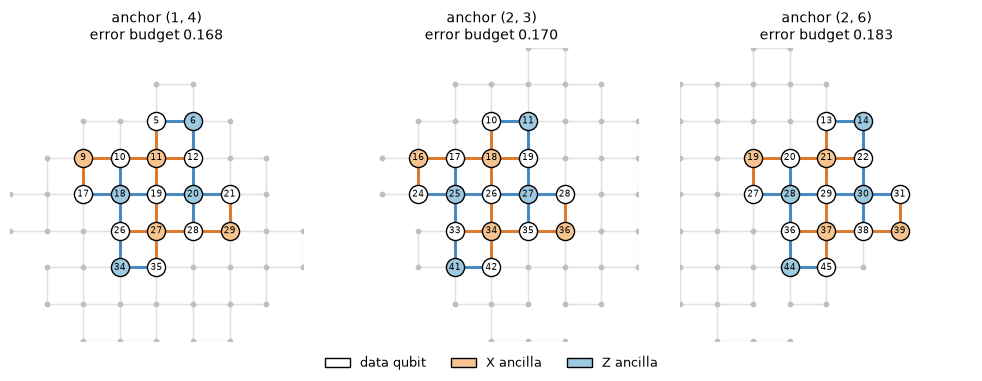

In [6]:
found = surface_code_placements(G, code, anchors=ANCHORS)
if ANCHORS is None:
    score = (lambda patch: backend.error_budget(patch, cal)) if cal is not None else (lambda patch: 0.0)
    found = sorted(found, key=score)[:n_best]
patches = found
for patch in patches:
    budget = f", error budget {backend.error_budget(patch, cal):.3f} per round" if cal is not None else ""
    print(f"{patch}{budget}")

from matplotlib.patches import Patch

ncols = min(len(patches), 4)
nrows = -(-len(patches) // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(3.4 * ncols, 3.6 * nrows), squeeze=False)
for ax, patch in zip(axes.flat, patches):
    budget = f"\nerror budget {backend.error_budget(patch, cal):.3f}" if cal is not None else ""
    plot_patch_on_chip(G, coords, patch, ax=ax, title=f"anchor {coords[patch.data_qubits[0]]}{budget}")
for ax in list(axes.flat)[len(patches):]:
    ax.axis("off")
fig.legend(handles=[Patch(facecolor="white", edgecolor="black", label="data qubit"),
                    Patch(facecolor=CHECK_COLOURS["X"], edgecolor="black", label="X ancilla"),
                    Patch(facecolor=CHECK_COLOURS["Z"], edgecolor="black", label="Z ancilla")],
           loc="lower center", ncols=3, fontsize=9, frameon=False)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

## 5. The circuit sent to IQM

`memory.iqm_memory_circuit` writes the experiment in IQM natives: `prx` and `cz`, a CNOT as `H CZ H` on its target
with Hadamards that meet cancelled, `measure_ff` + `cc_prx` for the mid-circuit readout and reset of rounds
$0 \ldots R-2$, and ordinary measurements of the last round's ancillas and of the data. Below, its gate counts for
$R = 1, 2, 3$ and the end of the OpenQASM program Braket receives for $R = 2$.

In [7]:
labels = backend.qubit_labels()
index = {q: i for i, q in enumerate(labels)}
for R in (1, 2, 3):
    ops = mem.iqm_memory_circuit(patches[0], R, "Z", qubit_index=index, num_qubits=len(labels)).count_ops()
    print(f"R = {R}: " + ", ".join(f"{k} {v}" for k, v in ops.items()))
program = backend.to_braket(mem.iqm_memory_circuit(patches[0], 2, "Z", qubit_index=index, num_qubits=len(labels)))
from braket.circuits.serialization import IRType

qasm = program.to_ir(ir_type=IRType.OPENQASM).source.splitlines()
print("\n".join(["..."] + [line for line in qasm if "measure" in line][-20:]))

R = 1: r 72, cz 24, measure 17
R = 2: r 140, cz 48, measure 17, MeasureFF 8, CCPRx 8
R = 3: r 208, cz 72, measure 17, MeasureFF 16, CCPRx 16
...
measure_ff(5) $29;
measure_ff(6) $9;
measure_ff(7) $34;
b[0] = measure $11;
b[1] = measure $18;
b[2] = measure $20;
b[3] = measure $27;
b[4] = measure $6;
b[5] = measure $29;
b[6] = measure $9;
b[7] = measure $34;
b[8] = measure $5;
b[9] = measure $10;
b[10] = measure $17;
b[11] = measure $12;
b[12] = measure $19;
b[13] = measure $26;
b[14] = measure $21;
b[15] = measure $28;
b[16] = measure $35;


/Users/alejomonbar/Documents/GitHub/qec-primitives-benchmark/.venv/lib/python3.12/site-packages/braket/experimental_capabilities/experimental_capability_context.py:126: UserWarning: You are enabling experimental capabilities. To view descriptions and restrictions of experimental capabilities, please review Amazon Braket Developer Guide (https://docs.aws.amazon.com/braket/latest/developerguide/braket-experimental-capabilities.html).
  warnings.warn(


## 6. Plan, then submit

One Braket task per patch, basis and round count; the plan checks every coupler is on the chip and every ancilla
in a feed-forward group, and prints the cost. A manifest is written after every task.

In [8]:
memory_plan = mem.plan(backend, patches, rounds=rounds, bases=BASES, shots=shots, p_2q_model=P_2Q_MODEL)
mem.print_plan(memory_plan)

Backend  : iqm_emerald
Patches  : 3 (surface_d3)
Sweep    : rounds [1, 2, 3, 5], bases ['Z', 'X'], 2000 shots each
Circuits : 24
Syndrome : last round only (mid-circuit outcomes are not returned on this device)
Estimate : 84.0 USD ($0.30/task + $0.00160/shot, one task per circuit; Braket credits 1:1 with USD)


In [10]:
manifest_path = mem.submit(memory_plan, backend, manifest_dir=DATA / "manifests", noise_model=noise, seed=7)

DeviceOfflineException: An error occurred (DeviceOfflineException) when calling the CreateQuantumTask operation: Device is not available. Status = OFFLINE

## 7. Harvest

Needs only the manifest. Unfinished tasks are reported and the run is harvested again later. Every shot's raw bits
(the last round's syndrome, then the data) are stored in `data/results/<device>/surface_code/memory/`, next to the
decoded logical error probability.

In [ ]:
manifests = sorted((DATA / "manifests" / backend.name).glob("*_surface_code_memory.json"), key=lambda p: p.name)
assert manifests, "no manifest yet - run the submit cell first"
manifest_path = manifests[-1]
print("harvesting", manifest_path.name)
saved = mem.harvest(manifest_path, backend, data_dir=DATA / "results")

## 8. Results

Logical error probability against rounds for every patch and basis, with the fit of
$P_L(R) = \tfrac{1}{2}[1 - A(1 - 2\varepsilon_L)^R]$ and its logical error per round $\varepsilon_L$. With the
last-round record $\varepsilon_L$ is an upper bound on what a decoder with the full history would reach on the same
device; across patches it is the ranking that carries over (section 3).

In [ ]:
results = mem.load_results(DATA / "results", backend.name, files={Path(saved).name})
fig, axes = plt.subplots(1, len(BASES), figsize=(5.5 * len(BASES), 4.2), sharey=True, squeeze=False)
print(f"{'patch':>34} {'basis':>6} " + "".join(f"{'R=' + str(R):>17}" for R in rounds) + f"{'eps_L per round':>22}")
for k, (patch, by_basis) in enumerate(sorted(results.items())):
    for ax, basis in zip(axes[0], BASES):
        if basis not in by_basis:
            continue
        rs = sorted(by_basis[basis])
        rate = np.array([by_basis[basis][R]["rate"] for R in rs])
        err = np.array([by_basis[basis][R]["err"] for R in rs])
        eps, eps_err, amplitude = mem.error_per_round(rs, rate)
        grid = np.linspace(min(rs), max(rs), 100)
        ax.errorbar(rs, rate, yerr=err, fmt="o", color=f"C{k}", mec="k", capsize=3, label=f"{patch.code.name}, {min(patch.qubits)}..")
        ax.plot(grid, (1 - amplitude * (1 - 2 * eps) ** grid) / 2, "-", color=f"C{k}", lw=1.2)
        print(f"{str(patch):>34} {basis:>6} " + "".join(f"  {r:.4f}+-{e:.4f}" for r, e in zip(rate, err))
              + f"   {eps:.4f} +- {eps_err:.4f} (A = {amplitude:.3f})")
for ax, basis in zip(axes[0], BASES):
    ax.set(xlabel="rounds $R$", title=f"{basis} memory ({'|0>' if basis == 'Z' else '|+>'}$_L$)", yscale="log")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
axes[0][0].set_ylabel("logical error probability (last-round record)")
fig.suptitle(backend.name)
fig.tight_layout()
fig.savefig(FIGURES / f"{backend.name}_surface_code_memory.pdf", bbox_inches="tight")
plt.show()